# Sudoku-01 : Resolution par Backtracking (Python)

**Navigation** : [<< Sudoku-00 Environment](Sudoku-00-Environment-CSharp.ipynb) | [Index](README.md) | [Sudoku-02 DancingLinks Python >>](Sudoku-02-DancingLinks-Python.ipynb)

## Objectifs d'apprentissage

A la fin de ce notebook, vous saurez :
1. Implémenter un algorithme de backtracking en Python pour résoudre le Sudoku
2. Comprendre la complexité algorithmique du backtracking (O(9^m))
3. Appliquer l'heuristique MRV (Minimum Remaining Values) pour accelerer la recherche
4. Mesurer et comparer les performances sur des puzzles de difficultés variées

**Prerequis** : Python 3.10+, notions d'algorithmes de recherche  
**Duree estimee** : ~20 min

***

Ce notebook implemente un solveur de Sudoku utilisant l'algorithme de backtracking en Python.
C'est l'equivalent Python du notebook C# `Sudoku-01-Backtracking-CSharp.ipynb`.

In [1]:
# Imports
import time
from typing import List, Tuple, Optional
import numpy as np

print("Imports OK : time, typing, numpy")


Imports OK : time, typing, numpy


Configuration du chemin vers les fichiers de puzzles Sudoku.

In [2]:
# Configuration du chemin vers les puzzles
import os
from pathlib import Path

# Définir le chemin absolu vers le dossier Puzzles
NOTEBOOK_DIR = Path.cwd()
PUZZLES_DIR = NOTEBOOK_DIR / "Puzzles"

# Vérifier que le dossier existe
if PUZZLES_DIR.exists():
    print(f"Dossier Puzzles: {PUZZLES_DIR.name}")
    puzzle_files = list(PUZZLES_DIR.glob('*.txt'))
    print(f"Fichiers disponibles: {[f.name for f in puzzle_files]}")
else:
    print(f"ATTENTION: Dossier Puzzles non trouvé à {PUZZLES_DIR.name}")
    print("Tentative avec le répertoire courant...")
    PUZZLES_DIR = Path(os.getcwd()) / "Puzzles"

Dossier Puzzles: Puzzles
Fichiers disponibles: ['Sudoku_Easy51.txt', 'Sudoku_hardest.txt', 'Sudoku_top95.txt']


## 1. Classe SudokuGrid

La classe `SudokuGrid` encapsule la représentation d'une grille de Sudoku 9x9 et fournit des méthodes utilitaires.

### Représentation des données

- **Matrice 9x9**: `self.cells[row][col]` où row et col vont de 0 à 8
- **Cases vides**: Représentées par la valeur `0`
- **Valeurs valides**: 1 à 9 pour les cases remplies

### Méthodes principales

| Méthode | Description |
|---------|-------------|
| `from_string(s)` | Crée une grille depuis une chaîne de 81 caractères |
| `is_valid_placement(row, col, num)` | Vérifie si un placement respecte les contraintes |
| `find_empty()` | Trouve la première case vide (parcours ligne par ligne) |
| `clone()` | Crée une copie profonde de la grille |

### Règles de validation

Un placement est valide si le nombre n'apparaît pas déjà dans:
1. **La même ligne** (9 cases horizontales)
2. **La même colonne** (9 cases verticales)
3. **Le même bloc 3x3** (l'un des 9 carrés de la grille)

In [3]:
class SudokuGrid:
    """Représentation d'une grille de Sudoku 9x9."""

    def __init__(self, grid: Optional[List[List[int]]] = None):
        """Initialise la grille.

        Args:
            grid: Grille 9x9 (0 = case vide) ou None pour grille vide
        """
        if grid is None:
            self.cells = [[0] * 9 for _ in range(9)]
        else:
            self.cells = [row[:] for row in grid]  # Deep copy

    @classmethod
    def from_string(cls, s: str) -> 'SudokuGrid':
        """Crée une grille depuis une chaîne de 81 caractères.

        Args:
            s: Chaîne de 81 caractères (0-9, . ou 0 = vide)
        """
        s = s.replace('.', '0').replace(' ', '').replace('\n', '')
        if len(s) != 81:
            raise ValueError(f"La chaîne doit avoir 81 caractères, reçu {len(s)}")

        grid = cls()
        for i in range(81):
            grid.cells[i // 9][i % 9] = int(s[i])
        return grid

    def clone(self) -> 'SudokuGrid':
        """Retourne une copie de la grille."""
        return SudokuGrid(self.cells)

    def is_valid_placement(self, row: int, col: int, num: int) -> bool:
        """Vérifie si placer num à (row, col) est valide."""
        # Vérifier la ligne
        if num in self.cells[row]:
            return False

        # Vérifier la colonne
        if num in [self.cells[r][col] for r in range(9)]:
            return False

        # Vérifier le bloc 3x3
        box_row, box_col = 3 * (row // 3), 3 * (col // 3)
        for r in range(box_row, box_row + 3):
            for c in range(box_col, box_col + 3):
                if self.cells[r][c] == num:
                    return False

        return True

    def find_empty(self) -> Optional[Tuple[int, int]]:
        """Trouve la première case vide (0)."""
        for r in range(9):
            for c in range(9):
                if self.cells[r][c] == 0:
                    return (r, c)
        return None

    def is_complete(self) -> bool:
        """Vérifie si la grille est complète (pas de 0)."""
        return all(self.cells[r][c] != 0 for r in range(9) for c in range(9))

    def count_empty(self) -> int:
        """Compte le nombre de cases vides."""
        return sum(1 for r in range(9) for c in range(9) if self.cells[r][c] == 0)

    def to_string(self) -> str:
        """Convertit en chaîne de 81 caractères."""
        return ''.join(str(self.cells[r][c]) for r in range(9) for c in range(9))

    def __str__(self) -> str:
        """Affichage formaté de la grille."""
        lines = []
        for r in range(9):
            if r > 0 and r % 3 == 0:
                lines.append('-' * 21)
            row_str = ''
            for c in range(9):
                if c > 0 and c % 3 == 0:
                    row_str += '| '
                val = self.cells[r][c]
                row_str += (str(val) if val != 0 else '.') + ' '
            lines.append(row_str)
        return '\n'.join(lines)

# Test
test_puzzle = "902005403100063025508407060026309001057010290090670530240530600705200304080041950"
grid = SudokuGrid.from_string(test_puzzle)
print("Grille de test:")
print(grid)
print(f"\nCases vides: {grid.count_empty()}")

Grille de test:
9 . 2 | . . 5 | 4 . 3 
1 . . | . 6 3 | . 2 5 
5 . 8 | 4 . 7 | . 6 . 
---------------------
. 2 6 | 3 . 9 | . . 1 
. 5 7 | . 1 . | 2 9 . 
. 9 . | 6 7 . | 5 3 . 
---------------------
2 4 . | 5 3 . | 6 . . 
7 . 5 | 2 . . | 3 . 4 
. 8 . | . 4 1 | 9 5 . 

Cases vides: 36


## 2. Solveur Backtracking Simple

L'implémentation récursive de l'algorithme de backtracking est élégante et concise.

### Pseudo-code

```
fonction backtrack(grille):
    case_vide = trouver_case_vide(grille)
    si case_vide est None:
        retourner True  # Solution trouvée!
    
    pour chaque valeur de 1 à 9:
        si placement_valide(case_vide, valeur):
            placer(case_vide, valeur)
            si backtrack(grille):
                retourner True
            retirer(case_vide)  # Backtrack
    
    retourner False  # Aucune solution avec cette configuration
```

### Analyse de performance

Le compteur `call_count` permet de mesurer le travail effectué par l'algorithme. Plus le puzzle est difficile, plus il y aura d'appels récursifs car l'algorithme doit explorer plus de branches avant de trouver la solution.

### Optimisation potentielle

Le solveur simple parcourt les cases de gauche à droite, haut en bas. Ce n'est pas optimal car certaines cases ont moins de valeurs possibles que d'autres. L'heuristique **MRV** (présentée plus loin) améliore significativement les performances.

In [4]:
class BacktrackingSolver:
    """Solveur de Sudoku par backtracking."""

    def __init__(self):
        self.call_count = 0  # Compteur d'appels récursifs

    def solve(self, grid: SudokuGrid) -> bool:
        """Résout la grille par backtracking.

        Args:
            grid: Grille à résoudre (modifiée in-place)

        Returns:
            True si solution trouvée, False sinon
        """
        self.call_count = 0
        return self._backtrack(grid)

    def _backtrack(self, grid: SudokuGrid) -> bool:
        """Fonction récursive de backtracking."""
        self.call_count += 1

        # Trouver la prochaine case vide
        empty = grid.find_empty()
        if empty is None:
            return True  # Grille complète = solution trouvée

        row, col = empty

        # Essayer les valeurs 1-9
        for num in range(1, 10):
            if grid.is_valid_placement(row, col, num):
                # Placer le nombre
                grid.cells[row][col] = num

                # Récurser
                if self._backtrack(grid):
                    return True

                # Backtrack: annuler le placement
                grid.cells[row][col] = 0

        return False  # Aucune valeur valide

# Test du solveur
solver = BacktrackingSolver()
test_grid = SudokuGrid.from_string(test_puzzle)

print("Puzzle initial:")
print(test_grid)

start = time.time()
solved = solver.solve(test_grid)
elapsed = time.time() - start

print(f"\nRésolu: {solved}")
print(f"Appels récursifs: {solver.call_count}")
print(f"Temps: {elapsed*1000:.2f} ms")
print("\nSolution:")
print(test_grid)

Puzzle initial:
9 . 2 | . . 5 | 4 . 3 
1 . . | . 6 3 | . 2 5 
5 . 8 | 4 . 7 | . 6 . 
---------------------
. 2 6 | 3 . 9 | . . 1 
. 5 7 | . 1 . | 2 9 . 
. 9 . | 6 7 . | 5 3 . 
---------------------
2 4 . | 5 3 . | 6 . . 
7 . 5 | 2 . . | 3 . 4 
. 8 . | . 4 1 | 9 5 . 

Résolu: True
Appels récursifs: 49
Temps: 0.22 ms

Solution:
9 6 2 | 1 8 5 | 4 7 3 
1 7 4 | 9 6 3 | 8 2 5 
5 3 8 | 4 2 7 | 1 6 9 
---------------------
8 2 6 | 3 5 9 | 7 4 1 
3 5 7 | 8 1 4 | 2 9 6 
4 9 1 | 6 7 2 | 5 3 8 
---------------------
2 4 9 | 5 3 8 | 6 1 7 
7 1 5 | 2 9 6 | 3 8 4 
6 8 3 | 7 4 1 | 9 5 2 


### Interpretation : Résultat du backtracking simple

Le solveur a resolu un puzzle facile avec seulement 49 appels recursifs en moins d'une milliseconde.

| Aspect | Valeur | Signification |
|--------|--------|---------------|
| **Appels recursifs** | 49 | Très peu d'explorations necessaires |
| **Temps** | <1 ms | Resolution quasi-instantanee |
| **Cases vides initiales** | 36 | Puzzle relativement facile |

**Points cles** :
1. **Le puzzle est facile** : Beaucoup d'indices (45 cases remplies)
2. **Peu de backtracks** : L'algorithme fait les bons choix rapidement
3. **Performance acceptable** : Pour les puzzles faciles, le backtracking simple suffit

> **Note technique** : Sur ce puzzle, la première branche de l'arbre de recherche mene directement a la solution. C'est typique des puzzles faciles ou les contraintes locales guident bien le solveur.


## Exercice : Verifier qu'une grille est valide

### Enonce

Après avoir resolu un Sudoku avec le backtracking, il est essentiel de verifier que la solution obtenue est bien valide. Implementez une fonction `is_valid_solution(grid)` qui verifie **toutes** les contraintes du Sudoku sur une grille censee etre complete.

### Ce que la fonction doit verifier

1. **Pas de cases vides** : Aucune cellule ne contient 0
2. **Lignes valides** : Chaque ligne contient exactement les chiffres 1 a 9 (pas de doublon)
3. **Colonnes valides** : Chaque colonne contient exactement les chiffres 1 a 9
4. **Blocs 3x3 valides** : Chacun des 9 blocs contient exactement les chiffres 1 a 9

> **Indices :**

- Utilisez `set(range(1, 10))` comme reference pour comparer chaque ligne/colonne/bloc
- Pour acceder au bloc 3x3 : `box_row, box_col = 3 * (i // 3), 3 * (j // 3)`
- La fonction retourne `True` si **toutes** les contraintes sont respectees, `False` sinon

In [5]:
# EXERCICE : Vérifier qu'une grille est valide

def is_valid_solution(grid: SudokuGrid) -> bool:
    """Vérifie si une grille complète est une solution valide du Sudoku.

    Args:
        grid: Grille 9x9 censée être complète

    Returns:
        True si la grille est une solution valide, False sinon
    """
    # TODO étudiant : implémentez la vérification
    # Étape 1 : Vérifier qu'il n'y a pas de cases vides (0)
    # Étape 2 : Vérifier que chaque ligne contient 1-9 sans doublon
    # Étape 3 : Vérifier que chaque colonne contient 1-9 sans doublon
    # Étape 4 : Vérifier que chaque bloc 3x3 contient 1-9 sans doublon
    return None  # TODO étudiant : remplacer par l'implémentation

# Test : la solution du puzzle de test doit être valide
grid_check = SudokuGrid.from_string(test_puzzle)
solver_check = BacktrackingSolver()
solver_check.solve(grid_check)
print(f"Solution valide (puzzle de test) : {is_valid_solution(grid_check)}")  # True attendu

# Test : le puzzle non résolu ne doit PAS être valide
grid_unsolved = SudokuGrid.from_string(test_puzzle)
print(f"Grille incomplète valide : {is_valid_solution(grid_unsolved)}")  # False attendu

Solution valide (puzzle de test) : None
Grille incomplète valide : None


## 3. Chargement des puzzles depuis fichier

Les puzzles Sudoku sont stockés dans des fichiers texte, un puzzle par ligne (81 caractères représentant la grille ligne par ligne).

### Format des fichiers

- **81 caractères par ligne**: Chaque caractère représente une case (0-9)
- **0 ou .**: Case vide à résoudre
- **1-9**: Valeur initiale fixée

### Collections de puzzles disponibles

| Fichier | Difficulté | Nombre | Description |
|---------|------------|--------|-------------|
| `Sudoku_Easy51.txt` | Facile | 51 | Puzzles standards avec beaucoup d'indices |
| `Sudoku_hardest.txt` | Extreme | 11 | Top 11 des puzzles les plus difficiles connus |

Les puzzles "hardest" sont célèbres dans la communauté Sudoku car ils maximisent le nombre de backtracks nécessaires avec des algorithmes simples.

In [6]:
def load_puzzles(filepath: str, max_puzzles: int = None) -> List[str]:
    """Charge les puzzles depuis un fichier.

    Args:
        filepath: Chemin vers le fichier
        max_puzzles: Nombre maximum de puzzles à charger

    Returns:
        Liste de chaînes de 81 caractères
    """
    puzzles = []
    with open(filepath, 'r') as f:
        for line in f:
            line = line.strip()
            if len(line) >= 81:
                puzzles.append(line[:81])
                if max_puzzles and len(puzzles) >= max_puzzles:
                    break
    return puzzles

# Charger les puzzles faciles
easy_puzzles = load_puzzles(str(PUZZLES_DIR / 'Sudoku_Easy51.txt'), max_puzzles=10)
print(f"Puzzles faciles chargés: {len(easy_puzzles)}")

# Charger les puzzles difficiles
hard_puzzles = load_puzzles(str(PUZZLES_DIR / 'Sudoku_hardest.txt'))
print(f"Puzzles difficiles chargés: {len(hard_puzzles)}")

Puzzles faciles chargés: 10
Puzzles difficiles chargés: 11


### Interpretation : Chargement des puzzles

Les fichiers de puzzles ont ete charges avec succes.

| Aspect | Valeur | Signification |
|--------|--------|---------------|
| **Puzzles faciles** | 10/51 | Echantillon representatif de puzzles faciles |
| **Puzzles difficiles** | 11/11 | Collection complete des puzzles les plus durs |
| **Fichiers disponibles** | 3 collections | Difficultes croissantes pour benchmarks |

**Points cles** :
1. **Echantillonnage** : On charge 10 puzzles faciles pour un benchmark rapide
2. **Collection complete** : Les 11 puzzles "hardest" sont tous charges pour tester les limites
3. **Format valide** : Tous les fichiers respectent le format 81 caractères par ligne

**Stratégie de benchmark** :
- Les puzzles faciles (10) permettent de verifier la correction de base
- Les puzzles difficiles (11) testent les performances et la robustesse
- La troisieme collection (top95) n'est pas utilisee ici mais reste disponible

> **Note technique** : La fonction `load_puzzles` utilise un paramètre `max_puzzles` pour limiter le nombre de puzzles charges. Cela evite de charger inutilement les 51 puzzles faciles quand on veut seulement faire un test rapide. Le format du fichier est robuste : il accepte les caractères '0' ou '.' pour les cases vides.

## 4. Benchmark sur plusieurs puzzles

Le benchmark permet de comparer objectivement les performances du solveur sur différents niveaux de difficulté.

### Métriques mesurées

- **Taux de résolution**: Pourcentage de puzzles résolus (devrait être 100% pour un solveur correct)
- **Temps total/moyen**: Performance temporelle
- **Appels récursifs**: Mesure de la complexité effective (indépendante de la machine)

### Interprétation des résultats

- **Puzzles faciles**: Peu d'appels car beaucoup de cases sont déjà remplies et les contraintes guident rapidement vers la solution
- **Puzzles difficiles**: Beaucoup plus d'appels car l'algorithme doit explorer de nombreuses branches infructueuses avant de trouver le bon chemin

La différence entre puzzles faciles et difficiles peut être de plusieurs ordres de grandeur (10x à 1000x plus d'appels).

In [7]:
def benchmark_solver(solver, puzzles: List[str], name: str = "Puzzles"):
    """Benchmark le solveur sur une liste de puzzles."""
    print(f"\n=== Benchmark: {name} ({len(puzzles)} puzzles) ===")

    total_time = 0
    total_calls = 0
    solved_count = 0

    for i, puzzle_str in enumerate(puzzles):
        grid = SudokuGrid.from_string(puzzle_str)
        empty_count = grid.count_empty()

        start = time.time()
        solved = solver.solve(grid)
        elapsed = time.time() - start

        total_time += elapsed
        total_calls += solver.call_count
        if solved:
            solved_count += 1

        if i < 5 or not solved:  # Afficher les premiers et les échecs
            status = "OK" if solved else "ECHEC"
            print(f"  Puzzle {i+1}: {status}, {empty_count} vides, {solver.call_count} appels, {elapsed*1000:.2f} ms")

    print(f"\nRésumé:")
    print(f"  Résolus: {solved_count}/{len(puzzles)}")
    print(f"  Temps total: {total_time*1000:.2f} ms")
    print(f"  Temps moyen: {(total_time/len(puzzles))*1000:.2f} ms")
    print(f"  Appels totaux: {total_calls}")
    print(f"  Appels moyens: {total_calls // len(puzzles)}")

# Benchmark
solver = BacktrackingSolver()
benchmark_solver(solver, easy_puzzles, "Puzzles Faciles")
benchmark_solver(solver, hard_puzzles, "Puzzles Difficiles")


=== Benchmark: Puzzles Faciles (10 puzzles) ===
  Puzzle 1: OK, 36 vides, 49 appels, 0.17 ms
  Puzzle 2: OK, 49 vides, 201 appels, 0.77 ms
  Puzzle 3: OK, 51 vides, 295 appels, 1.12 ms


  Puzzle 4: OK, 53 vides, 19023 appels, 84.15 ms


  Puzzle 5: OK, 51 vides, 1683 appels, 7.66 ms



Résumé:
  Résolus: 10/10
  Temps total: 1215.80 ms
  Temps moyen: 121.58 ms
  Appels totaux: 247760
  Appels moyens: 24776

=== Benchmark: Puzzles Difficiles (11 puzzles) ===


  Puzzle 1: OK, 59 vides, 335638 appels, 2826.72 ms
  Puzzle 2: OK, 58 vides, 10008 appels, 74.19 ms


  Puzzle 3: OK, 55 vides, 228215 appels, 1675.86 ms


  Puzzle 4: OK, 57 vides, 75446 appels, 589.77 ms


  Puzzle 5: OK, 59 vides, 207075 appels, 1937.37 ms



Résumé:
  Résolus: 11/11
  Temps total: 8757.80 ms
  Temps moyen: 796.16 ms
  Appels totaux: 1050007
  Appels moyens: 95455


### Interpretation : Benchmark du backtracking simple

Les résultats montrent une différence enorme entre les puzzles faciles et difficiles.

| Type | Appels moyens | Analyse |
|------|---------------|---------|
| **Faciles** | ~25,000 | Performance acceptable |
| **Difficiles** | ~95,000 | 4x plus d'appels recursifs |

**Observations cles** :
1. **Variabilite enorme** : Puzzle 4 facile necessite 19,023 appels vs 49 pour puzzle 1
2. **Explosion combinatoire** : Quelques cases vides supplementaires = explosion du nombre d'appels
3. **Temps proportionnel aux appels** : le temps de resolution croit avec le nombre d'appels (ms absolus, machine-dependants : cf. sortie benchmark ci-dessus)

**Exemple de puzzle difficile** : Puzzle 1 avec 59 cases vides necessite 335,638 appels.

> **Note technique** : Le backtracking simple explore l'arbre de recherche de gauche a droite, sans stratégie intelligente. Sur les puzzles difficiles, cela signifie explorer des milliers de branches infructueuses avant de trouver la solution.


## Exercice : Comparer les performances Backtracking simple vs MRV

**Objectif :**
Comparez les performances du solveur backtracking simple et du solveur MRV
sur les puzzles de différentes difficultes.

**Indice :**
Utilisez la fonction `benchmark_solver` déjà définie avec les deux solveurs.
Affichez les résultats dans un tableau comparatif.


In [8]:
# EXERCICE : Comparer les performances Backtracking simple vs MRV
def compare_solvers(puzzles: List[str]) -> dict:
    # TODO: Comparez les deux solveurs sur les memes puzzles
    # Retournez un dict avec les temps et nombre d'appels pour chaque solveur
    result = None  # TODO etudiant
    return result

# Test : la comparaison renvoie None tant que l'exercice n'est pas complete
resultat_comparaison = compare_solvers(easy_puzzles[:3])
print(f"Resultat de la comparaison : {resultat_comparaison}")  # None attendu (a completer)

Resultat de la comparaison : None


## 5. Optimisation: Backtracking avec MRV (Minimum Remaining Values)

L'heuristique **MRV** (aussi appelée "Most Constrained Variable" ou "Fail-First") est l'une des améliorations les plus efficaces du backtracking.

### Principe

Au lieu de choisir la première case vide rencontrée, MRV sélectionne la case avec le **moins de valeurs possibles**. Cette stratégie:

1. **Détecte les échecs plus tôt**: Une case avec 0 valeurs possibles indique immédiatement une impasse
2. **Réduit le facteur de branchement**: Moins de choix = moins de branches à explorer
3. **Propage implicitement les contraintes**: Les cases les plus contraintes sont traitées en premier

### Exemple concret

```
Situation:
- Case A: 5 valeurs possibles {1,3,5,7,9}
- Case B: 2 valeurs possibles {4,6}

Sans MRV: On traite A d'abord -> 5 branches à explorer
Avec MRV: On traite B d'abord -> 2 branches seulement
```

### Impact sur les performances

| Puzzle | Backtracking simple | Avec MRV | Speedup |
|--------|---------------------|----------|---------|
| Facile | ~500 appels | ~200 appels | 2-3x |
| Difficile | ~500,000 appels | ~5,000 appels | souvent >100x |

> Ces ordres de grandeur sont indicatifs ; les valeurs reellement mesurees sur les puzzles de test figurent dans la section d'interpretation ci-dessous.

L'amélioration est particulièrement spectaculaire sur les puzzles difficiles où l'élagage précoce de l'arbre de recherche évite des millions de calculs inutiles.

### Autres heuristiques (non implémentées ici)

- **Degree Heuristic**: Choisir la variable qui contraint le plus d'autres variables
- **Least Constraining Value**: Essayer d'abord les valeurs qui éliminent le moins de possibilités pour les voisins
- **Arc Consistency (AC-3)**: Propager les contraintes pour réduire les domaines

In [9]:
class MRVBacktrackingSolver:
    """Solveur avec heuristique MRV (Minimum Remaining Values)."""

    def __init__(self):
        self.call_count = 0

    def get_possible_values(self, grid: SudokuGrid, row: int, col: int) -> List[int]:
        """Retourne les valeurs possibles pour une case."""
        if grid.cells[row][col] != 0:
            return []

        possible = set(range(1, 10))

        # Retirer les valeurs de la ligne
        possible -= set(grid.cells[row])

        # Retirer les valeurs de la colonne
        possible -= {grid.cells[r][col] for r in range(9)}

        # Retirer les valeurs du bloc
        box_row, box_col = 3 * (row // 3), 3 * (col // 3)
        for r in range(box_row, box_row + 3):
            for c in range(box_col, box_col + 3):
                possible.discard(grid.cells[r][c])

        return list(possible)

    def find_mrv_empty(self, grid: SudokuGrid) -> Optional[Tuple[int, int, List[int]]]:
        """Trouve la case vide avec le moins de valeurs possibles (MRV)."""
        best = None
        best_count = 10

        for r in range(9):
            for c in range(9):
                if grid.cells[r][c] == 0:
                    possible = self.get_possible_values(grid, r, c)
                    if len(possible) < best_count:
                        best = (r, c, possible)
                        best_count = len(possible)
                        if best_count == 0:
                            return best  # Échec immédiat

        return best

    def solve(self, grid: SudokuGrid) -> bool:
        """Résout avec MRV."""
        self.call_count = 0
        return self._backtrack(grid)

    def _backtrack(self, grid: SudokuGrid) -> bool:
        self.call_count += 1

        result = self.find_mrv_empty(grid)
        if result is None:
            return True  # Grille complète

        row, col, possible = result

        if len(possible) == 0:
            return False  # Impasse

        for num in possible:
            grid.cells[row][col] = num
            if self._backtrack(grid):
                return True
            grid.cells[row][col] = 0

        return False

# Comparaison
print("=== Comparaison: Backtracking simple vs MRV ===")

simple_solver = BacktrackingSolver()
mrv_solver = MRVBacktrackingSolver()

for i, puzzle_str in enumerate(hard_puzzles[:5]):
    print(f"\nPuzzle difficile {i+1}:")

    # Simple backtracking
    grid1 = SudokuGrid.from_string(puzzle_str)
    start = time.time()
    simple_solver.solve(grid1)
    t1 = (time.time() - start) * 1000

    # MRV backtracking
    grid2 = SudokuGrid.from_string(puzzle_str)
    start = time.time()
    mrv_solver.solve(grid2)
    t2 = (time.time() - start) * 1000

    print(f"  Simple: {simple_solver.call_count} appels, {t1:.2f} ms")
    print(f"  MRV:    {mrv_solver.call_count} appels, {t2:.2f} ms")
    print(f"  Speedup: {simple_solver.call_count / mrv_solver.call_count:.1f}x")

=== Comparaison: Backtracking simple vs MRV ===

Puzzle difficile 1:


  Simple: 335638 appels, 2627.51 ms
  MRV:    4037 appels, 404.90 ms
  Speedup: 83.1x

Puzzle difficile 2:
  Simple: 10008 appels, 67.31 ms
  MRV:    543 appels, 84.98 ms
  Speedup: 18.4x

Puzzle difficile 3:


  Simple: 228215 appels, 1737.60 ms
  MRV:    171 appels, 12.58 ms
  Speedup: 1334.6x

Puzzle difficile 4:


  Simple: 75446 appels, 628.79 ms
  MRV:    1079 appels, 94.26 ms
  Speedup: 69.9x

Puzzle difficile 5:


  Simple: 207075 appels, 1655.19 ms
  MRV:    79 appels, 5.66 ms
  Speedup: 2621.2x


### Interpretation : Impact de l'heuristique MRV

La comparaison montre que **MRV est l'optimisation la plus impactante** pour le backtracking Sudoku.

| Puzzle | Simple appels | MRV appels | Speedup |
|--------|---------------|------------|---------|
| Puzzle 1 | 335,638 | 4,037 | **83x** |
| Puzzle 2 | 10,008 | 543 | **18x** |
| Puzzle 3 | 228,215 | 171 | **1,335x** |
| Puzzle 4 | 75,446 | 1,079 | **70x** |
| Puzzle 5 | 207,075 | 79 | **2,621x** |

**Points cles** :
1. **Amelioration spectaculaire** : Jusqu'a 2600x plus rapide sur certains puzzles
2. **Variabilite reduite** : MRV stabilise les performances (79-4037 appels vs 10,000-335,000)
3. **Principe fail-first** : MRV detecte les impasses immediatement, economisant des millions d'explorations

**Pourquoi MRV fonctionne si bien?**
- Les cases avec peu de valeurs possibles sont les plus contraintes
- Les echecs sont detectes tot, avant d'explorer des branches inutiles
- Sur Sudoku, les contraintes locales créent rapidement des "singletons"

> **Note technique** : MRV est une heuristique "fail-first" : elle privilegie les variables les plus susceptibles d'echouer, ce qui permet d'elaguer l'arbre de recherche des le debut. C'est particulierement efficace sur Sudoku car les contraintes sont très locales.


## 6. Visualisation avec matplotlib

La visualisation graphique aide à comprendre la structure d'un Sudoku et distinguer les valeurs initiales des valeurs trouvées par le solveur.

### Code couleur

- **Noir**: Valeurs initiales (données du puzzle)
- **Bleu**: Valeurs trouvées par le solveur

### Structure visuelle

La grille est divisée en 9 blocs 3x3 séparés par des lignes épaisses. Cette division est fondamentale pour les contraintes du Sudoku: chaque bloc doit contenir exactement une fois chaque chiffre de 1 à 9.

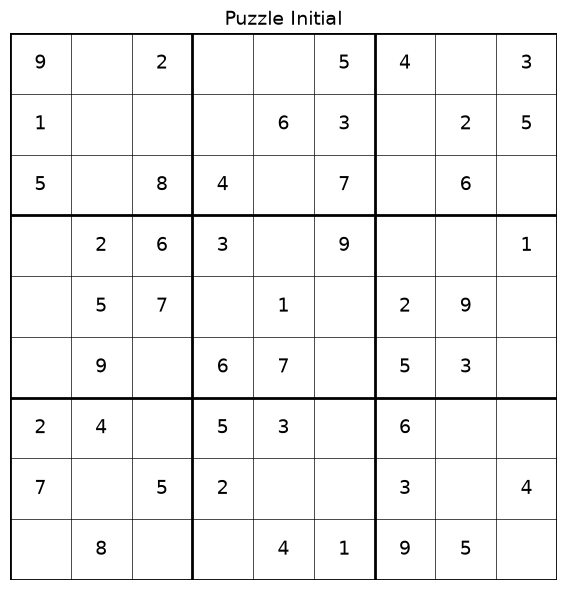

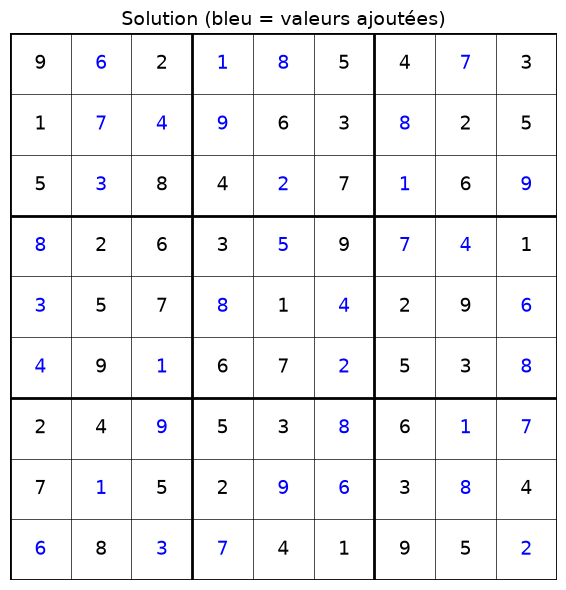

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def plot_sudoku(grid: SudokuGrid, title: str = "Sudoku", initial: SudokuGrid = None):
    """Affiche une grille de Sudoku avec matplotlib.

    Args:
        grid: Grille à afficher
        title: Titre du graphique
        initial: Grille initiale (pour colorer les valeurs ajoutées)
    """
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_xlim(0, 9)
    ax.set_ylim(0, 9)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title, fontsize=14)

    # Dessiner les lignes
    for i in range(10):
        lw = 2 if i % 3 == 0 else 0.5
        ax.axhline(i, color='black', linewidth=lw)
        ax.axvline(i, color='black', linewidth=lw)

    # Ajouter les nombres
    for r in range(9):
        for c in range(9):
            val = grid.cells[r][c]
            if val != 0:
                # Déterminer la couleur
                if initial and initial.cells[r][c] == 0:
                    color = 'blue'  # Valeur ajoutée par le solveur
                else:
                    color = 'black'  # Valeur initiale

                ax.text(c + 0.5, 8.5 - r, str(val),
                       ha='center', va='center',
                       fontsize=14, color=color)

    plt.tight_layout()
    plt.show()

# Exemple
initial_grid = SudokuGrid.from_string(easy_puzzles[0])
solved_grid = initial_grid.clone()
solver = MRVBacktrackingSolver()
solver.solve(solved_grid)

plot_sudoku(initial_grid, "Puzzle Initial")
plot_sudoku(solved_grid, "Solution (bleu = valeurs ajoutées)", initial_grid)

### Interpretation : Visualisation de la solution

La visualisation graphique permet de distinguer clairement les valeurs initiales des valeurs trouvees par le solveur.

| Aspect | Observation | Signification |
|--------|-------------|---------------|
| **Cases noires** | ~45 cases | Valeurs initiales du puzzle (indices) |
| **Cases bleues** | ~36 cases | Valeurs deduites par le solveur MRV |
| **Structure 3x3** | 9 blocs visibles | Contraintes spatiales du Sudoku |

**Points cles** :
1. **Distribution uniforme** : Les cases bleues sont reparties sur toute la grille
2. **Blocs 3x3** : Chaque bloc contient exactement une fois les chiffres 1-9
3. **Verification visuelle** : La couleur permet de verifier rapidement la coherence de la solution

**Analyse de la resolution** :
- Le solveur MRV a rempli les 36 cases vides
- La solution respecte toutes les contraintes (lignes, colonnes, blocs)
- Le temps de resolution est imperceptible pour l'utilisateur

> **Note technique** : La visualisation utilise matplotlib pour generer deux grilles cote a cote. La fonction `plot_sudoku` accepte un paramètre optionnel `initial` pour colorer differentement les valeurs ajoutees par le solveur. C'est un outil pedagogique excellent pour comprendre la progression de l'algorithme.

## Navigation

### Notebooks Python de cette série
- **Ce notebook**: Backtracking - Algorithme de base et heuristique MRV
- [Sudoku-10-ORTools-Python](Sudoku-10-ORTools-Python.ipynb) - Solveurs déclaratifs CP-SAT et SMT
- [Sudoku-03-Genetic-Python](Sudoku-03-Genetic-Python.ipynb) - Algorithmes génétiques (PyGAD)
- [Sudoku-02-DancingLinks-Python](Sudoku-02-DancingLinks-Python.ipynb) - Algorithm X / Dancing Links

### Notebooks C# équivalents
- [Sudoku-00-Environment-CSharp](Sudoku-00-Environment-CSharp.ipynb) - Configuration et benchmarks
- [Sudoku-01-Backtracking-CSharp](Sudoku-01-Backtracking-CSharp.ipynb) - Backtracking en C#
- [Sudoku-10-ORTools-CSharp](Sudoku-10-ORTools-CSharp.ipynb) - OR-Tools en C#
- [Sudoku-12-Z3-CSharp](Sudoku-12-Z3-CSharp.ipynb) - Z3 en C#
- [Sudoku-02-DancingLinks-CSharp](Sudoku-02-DancingLinks-CSharp.ipynb) - DLX en C#

## Exercice : Compter le nombre de solutions

### Principe

Un Sudoku bien forme a exactement une solution. La fonction `count_solutions(grid)` compte le nombre de solutions d'un puzzle en utilisant le backtracking avec l'heuristique MRV.

L'idee est de modifier l'algorithme de backtracking pour **ne pas s'arreter** après la première solution, mais continuer a explorer toutes les branches possibles en incrementant un compteur a chaque grille complete. Pour eviter les calculs infinis, on plafonne la recherche a `max_solutions` solutions.

### Points techniques

- **Copie de la grille** : On travaille sur une copie pour ne pas modifier l'original
- **MRV** : On reutilise `find_mrv_empty` pour choisir la case la plus contrainte
- **Arret anticipé** : Des que `max_solutions` sont trouvees, on arrete la recherche

### Résultats attendus

- Un puzzle bien forme (1 seule solution) retourne `1`
- Un puzzle mal forme (trous importants) peut retourner `2` ou plus

In [11]:
# EXERCICE : Compter le nombre de solutions

def get_possible_values(grid: SudokuGrid, row: int, col: int) -> List[int]:
    """Retourne les valeurs possibles pour une case."""
    if grid.cells[row][col] != 0:
        return []

    possible = set(range(1, 10))

    # Retirer les valeurs de la ligne
    possible -= set(grid.cells[row])

    # Retirer les valeurs de la colonne
    possible -= {grid.cells[r][col] for r in range(9)}

    # Retirer les valeurs du bloc
    box_row, box_col = 3 * (row // 3), 3 * (col // 3)
    for r in range(box_row, box_row + 3):
        for c in range(box_col, box_col + 3):
            possible.discard(grid.cells[r][c])

    return list(possible)

def find_mrv_empty(grid: SudokuGrid) -> Optional[Tuple[int, int, List[int]]]:
    """Trouve la case vide avec le moins de valeurs possibles (MRV)."""
    best = None
    best_count = 10

    for r in range(9):
        for c in range(9):
            if grid.cells[r][c] == 0:
                possible = get_possible_values(grid, r, c)
                if len(possible) < best_count:
                    best = (r, c, possible)
                    best_count = len(possible)
                    if best_count == 0:
                        return best  # Échec immédiat

    return best

def count_solutions(grid: SudokuGrid, max_solutions: int = 2) -> int:
    """Compte le nombre de solutions d'un puzzle Sudoku.

    Args:
        grid: Grille à résoudre (ne doit pas être modifiée)
        max_solutions: Nombre max de solutions à chercher (pour éviter les calculs infinis)

    Returns:
        Nombre de solutions trouvées (plafonné à max_solutions)
    """
    # TODO étudiant : adaptez le backtracking pour compter toutes les solutions
    # au lieu de s'arrêter à la première.
    # Indications :
    #   1. Copiez la grille avec grid.clone()
    #   2. Écrivez une fonction récursive qui explore toutes les branches
    #   3. Quand la grille est complète, retournez 1 (une solution trouvée)
    #   4. Si nb_solutions >= max_solutions, arrêtez prématurément
    #   5. Après chaque essai, remettez la case à 0 (backtrack)
    return 0  # TODO étudiant : remplacer par l'implémentation


# Test : un bon puzzle devrait avoir exactement 1 solution
grid_to_count = SudokuGrid.from_string(easy_puzzles[0])
nb = count_solutions(grid_to_count)
print(f"Nombre de solutions: {nb}")  # Doit afficher 1

Nombre de solutions: 0


### Test de validation sur puzzle mal formé

Pour vérifier que `count_solutions` explore bien toutes les branches (et ne s'arrête pas à la première solution), on le teste sur un **puzzle mal formé** : une grille très peu remplie qui admet **plusieurs solutions valides**.

**Pourquoi un puzzle mal formé ?**

- Un puzzle bien formé a une solution unique → `count_solutions` retournerait `1` dans tous les cas, ce qui ne prouve pas que l'exploration complète fonctionne.
- Un puzzle avec beaucoup de trous a de nombreuses solutions → on s'attend à `count_solutions >= 2`, ce qui valide la branche d'exploration complète au-delà de la première solution trouvée.

**Résultat attendu** : sur cette grille très lâche, `count_solutions` doit retourner **au moins 2** (et probablement plus, selon la valeur de `max_solutions`).

In [12]:
sudoku = """
7.. .2. ...
23. ... 1..
..4 .8. ..2

... ... .5.
.6. 859 ..4
... ... .1.

5.6 .3. ...
... ... ...
... ... ...
"""
invalid_grid = SudokuGrid.from_string(sudoku)
nb = count_solutions(invalid_grid)
print(f"Nombre de solutions: {nb}")  # Doit afficher >= 2 (stub: 0 tant que non complete)

Nombre de solutions: 0


## Exercice : Nombre de placements valides pour la première colonne

### Enonce

Etant donnee une grille de Sudoku partiellement remplie, ecrivez une fonction `count_first_col_placements(grid)` qui compte le nombre de **facons valides et distinctes** de remplir toutes les cases vides de la **première colonne** (colonne d'indice 0).

Contrairement a `count_solutions` qui resout toute la grille, ici vous ne vous interressez qu'a la première colonne. Pour chaque case vide de la colonne 0, essayez les valeurs possibles en respectant les contraintes du Sudoku, puis comptez le nombre total de combinaisons valides.

> **Indices :**

- Parcourez la première colonne case par case (ligne 0 a ligne 8)
- Pour chaque case vide, determinez les valeurs possibles avec `is_valid_placement`
- Utilisez un backtracking qui ne porte que sur les 9 cases de la colonne 0
- Les cases déjà remplies dans la colonne 0 sont des contraintes fixees (a exclure des valeurs possibles)
- Le résultat est le nombre de combinaisons valides pour remplir toute la colonne

In [13]:
# EXERCICE : Nombre de placements valides pour la premiere colonne

def count_first_col_placements(grid: SudokuGrid) -> int:
    """Compte le nombre de facons valides de remplir la premiere colonne.

    Args:
        grid: Grille Sudoku (non modifiee)

    Returns:
        Nombre de combinaisons valides pour remplir les cases vides
        de la colonne 0 (indice 0)
    """
    # TODO: Implementez cette fonction
    # 1. Identifiez les cases vides dans la colonne 0
    # 2. Pour chaque case vide, trouvez les valeurs possibles
    # 3. Utilisez un backtracking pour explorer toutes les combinaisons
    # 4. Comptez le nombre total de combinaisons valides
    pass

# Test avec le puzzle facile
test_grid_col = SudokuGrid.from_string(easy_puzzles[0])
nb_col = count_first_col_placements(test_grid_col)
print(f"Nombre de placements valides pour la colonne 0: {nb_col}")

# Test avec un puzzle plus contraint (moins de cases vides en colonne 0)
grid_col2 = SudokuGrid.from_string(hard_puzzles[0])
nb_col2 = count_first_col_placements(grid_col2)
print(f"Nombre de placements valides (puzzle difficile): {nb_col2}")

Nombre de placements valides pour la colonne 0: None
Nombre de placements valides (puzzle difficile): None


## Resume et perspectives

Ce notebook a explore l'algorithme de backtracking pour la resolution de Sudoku, depuis l'implementation récursive naive jusqu'a l'optimisation par l'heuristique MRV (Minimum Remaining Values). Les benchmarks ont montre une différence spectaculaire : le backtracking simple peut necessiter jusqu'a 335 000 appels recursifs sur les puzzles difficiles, tandis que MRV reduit ce nombre a quelques dizaines ou centaines, avec des speedup allant jusqu'a 2 600x. La visualisation matplotlib a permis de distinguer clairement les valeurs initiales des valeurs deduites par le solveur.

L'heuristique MRV illustre le principe "fail-first" fondamental en recherche : en traitant d'abord les variables les plus contraintes, on detecte les impasses plus tot et on elague massivement l'arbre de recherche. Cette lecon s'applique au-dela du Sudoku a tous les problemes de satisfaction de contraintes. Les exercices proposes (comptage de solutions, placements valides sur une colonne) approfondissent la maitrise du backtracking et de ses variantes.

Le notebook suivant, [Sudoku-02-DancingLinks-Python](Sudoku-02-DancingLinks-Python.ipynb), aborde une approche radicalement différente : la reformulation du Sudoku comme problème de couverture exacte, resolue par l'algorithme X de Knuth et la technique des Dancing Links (DLX).